In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.stats import mannwhitneyu

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "03_anotado.h5ad")

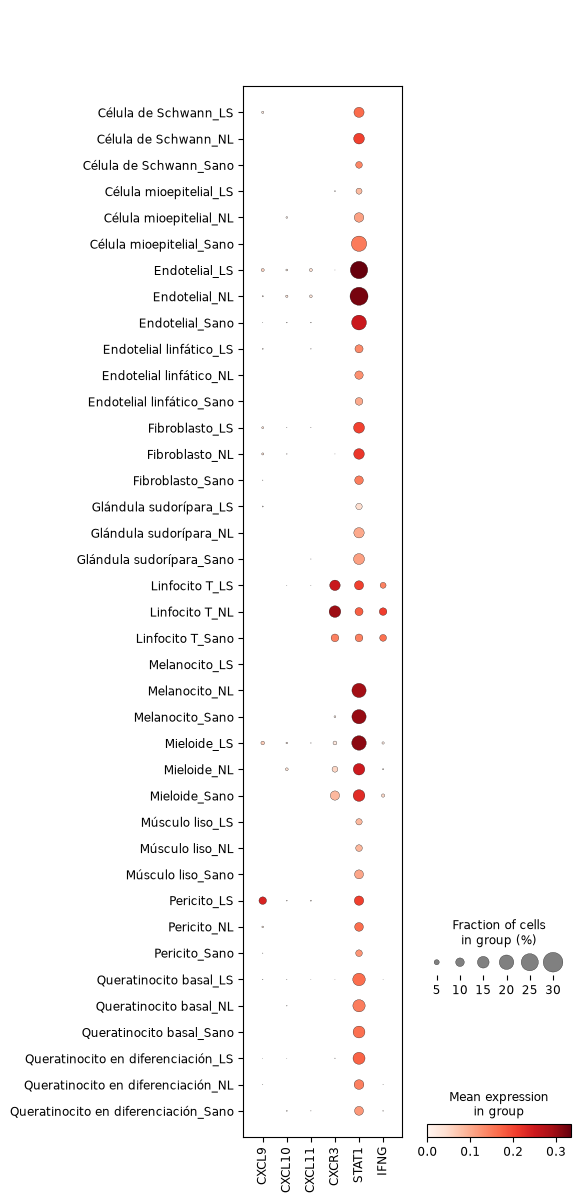

In [2]:
sc.pl.dotplot(adata, ["CXCL9", "CXCL10", "CXCL11", "CXCR3", "STAT1", "IFNG"],
              groupby=["tipo", "condicion"], show=False)
plt.savefig(DIR_FIGURAS / "dotplot_eje_CXCL_CXCR3.png", dpi=150, bbox_inches="tight")

In [4]:
quimiocinas = ["CXCL9", "CXCL10", "CXCL11"]
tipos = ["Endotelial", "Fibroblasto", "Mieloide", "Queratinocito basal"]

df = sc.get.obs_df(adata, keys=["tipo", "condicion", "muestra"] + quimiocinas, layer="counts")
df["CXCL_positiva"] = (df[quimiocinas] > 0).any(axis=1)

tabla = (df[df["tipo"].isin(tipos)]
         .groupby(["tipo", "condicion", "muestra"], observed=True)["CXCL_positiva"]
         .agg(n="size", positivas="sum").reset_index())
tabla["pct"] = (100 * tabla["positivas"] / tabla["n"]).round(2)
tabla = tabla[tabla["n"] >= 30]
tabla.to_csv(DIR_TABLAS / "quimiocinas_por_muestra.csv", index=False)
tabla

,tipo,condicion,muestra,n,positivas,pct
0,Endotelial,LS,486_LS,556,35,6.29
1,Endotelial,LS,BIO023_LS,361,43,11.91
2,Endotelial,LS,DER114_LS,278,2,0.72
3,Endotelial,LS,DER115_LS,431,16,3.71
4,Endotelial,LS,DER119_LS,413,10,2.42
5,Endotelial,LS,DER120_LS,160,1,0.62
6,Endotelial,NL,486_NL,55,0,0.00
7,Endotelial,NL,DER114_NL,307,2,0.65
8,Endotelial,NL,DER115_NL,394,29,7.36
9,Endotelial,NL,DER119_NL,226,8,3.54


In [5]:
filas = []
for tipo in tipos:
    d = tabla[tabla["tipo"] == tipo]
    g = {c: d.loc[d["condicion"] == c, "pct"] for c in ["Sano", "NL", "LS"]}
    fila = {"tipo": tipo, **{f"n_{c}": len(v) for c, v in g.items()}}
    for c in ["NL", "LS"]:
        if min(len(g[c]), len(g["Sano"])) >= 3:
            fila[f"p_{c}_vs_Sano"] = mannwhitneyu(g[c], g["Sano"]).pvalue
        else:
            fila[f"p_{c}_vs_Sano"] = np.nan
    filas.append(fila)

res = pd.DataFrame(filas)
res.round(3).to_csv(DIR_TABLAS / "quimiocinas_estadistica.csv", index=False)
res.round(3)

,tipo,n_Sano,n_NL,n_LS,p_NL_vs_Sano,p_LS_vs_Sano
0,Endotelial,6,5,6,0.519,0.092
1,Fibroblasto,5,4,6,0.867,0.028
2,Mieloide,0,2,3,NaN,NaN
3,Queratinocito basal,4,4,6,0.453,0.149


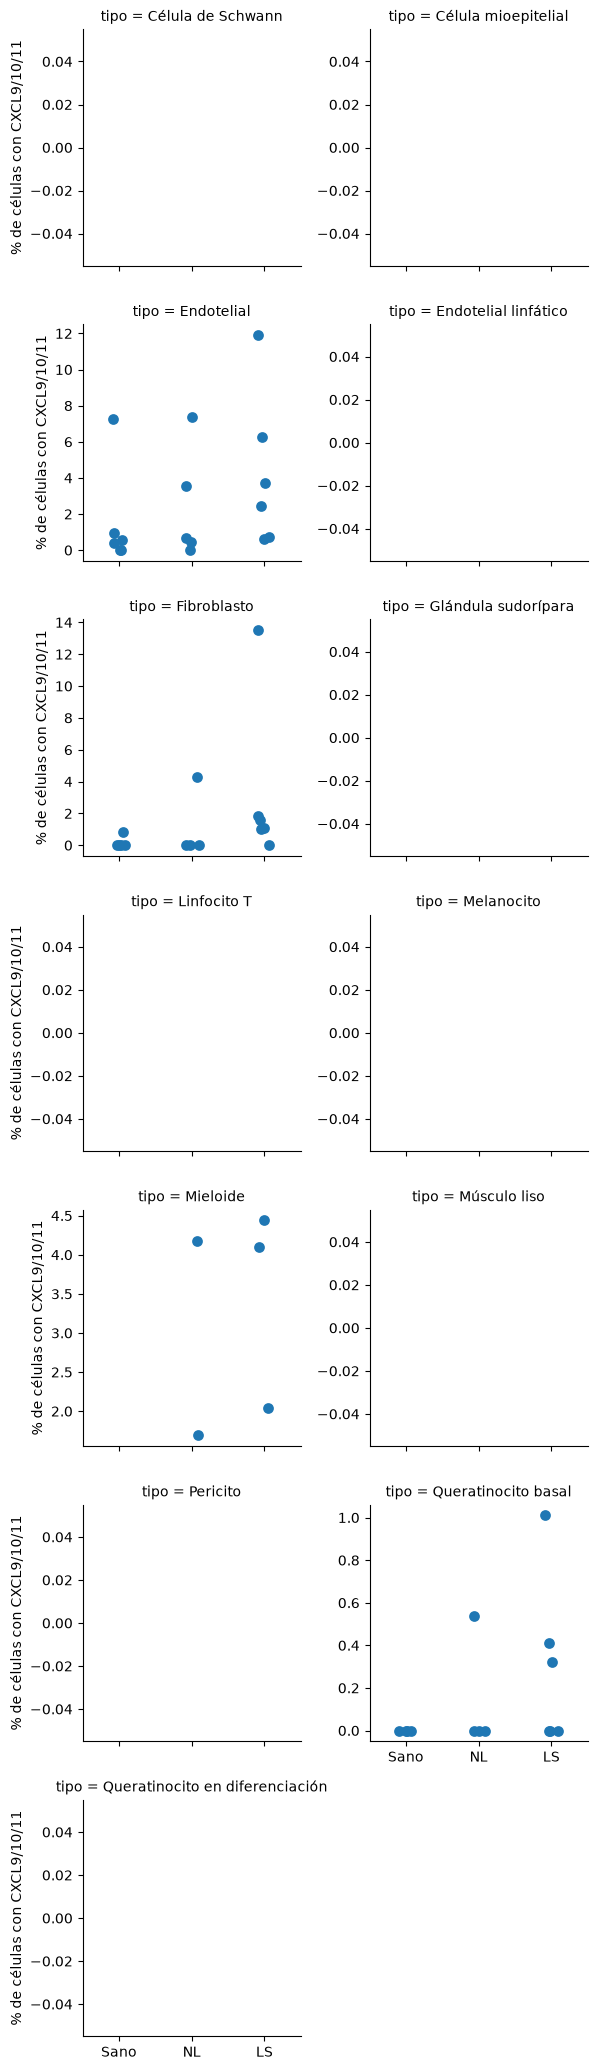

In [6]:
g = sns.catplot(data=tabla, x="condicion", y="pct", col="tipo", kind="strip",
                col_wrap=2, order=["Sano", "NL", "LS"], sharey=False, height=3, s=60)
g.set_axis_labels("", "% de células con CXCL9/10/11")
g.savefig(DIR_FIGURAS / "quimiocinas_por_condicion.png", dpi=150, bbox_inches="tight")